# ERank vs Random vs Uniform — структурный прунинг ResNet-20

**Вопрос:** лучше ли ERank определяет, **сколько внутренних каналов оставить в каждом блоке**, чем случайное или равномерное распределение сжатия?

1. Обучаем ResNet-20 на CIFAR-10 и сохраняем checkpoint (либо загружаем готовый).
2. По активациям **обученной** сети получаем ERank девяти блоков и один QR-порядок каналов на блок.
3. Сравниваем **ERank**, **Random allocation** и **Uniform**. Все удаляют *одинаковое суммарное число каналов*; конкретные каналы во всех случаях выбирает **один и тот же QR**.
4. Смотрим accuracy сразу после удаления, после пересчёта BatchNorm и после одинакового fine-tuning. Random повторяем с разными seed.
5. В конце (по желанию) обучаем найденные архитектуры **с нуля**.

**Ограничение:** одинаковое число удалённых каналов ≠ одинаковое число параметров/FLOPs. Их считаем отдельно. Официальный **test не используется** при разработке. Используем ERank по **сингулярным числам общей центрированной матрицы** (Roy–Vetterli), не метрику по ковариациям отдельных изображений из статьи.

## 1. Настройки и модель

`QUICK=True` — проверить, что всё работает, даже на CPU. Для содержательного эксперимента на GPU поставь `QUICK=False`. `BASE_MODE='load'` позволит пропустить длительное обучение, если checkpoint уже сохранён. В Colab файлы в `/content` исчезают после сброса окружения: для постоянного хранения можно предварительно подключить Google Drive и изменить `OUT`.

In [11]:
import copy, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.linalg import qr
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from IPython.display import display

SEED = 42
QUICK = False                     # True: короткая проверка на CPU
BASE_MODE = 'train'              # 'train' или 'load'
BASE_EPOCHS = 150 if not QUICK else 4
FT_EPOCHS = 10 if not QUICK else 2
TRAIN_SIZE = 45_000 if not QUICK else 5_000
VAL_SIZE = 5_000 if not QUICK else 2_000
CALIB_SIZE = 4_096              # из train, без аугментаций
POSITIONS = 1024                   # позиций из каждой карты признаков
BN_CALIB_SIZE = 2_048
BATCH_SIZE = 128
MIN_WIDTH = 4
RANDOM_SEEDS = [11, 22, 33, 44, 55]

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cpu':
    torch.set_num_threads(2)
OUT = Path('results/erank_v2_quick' if QUICK else 'results/erank_v2_full')
OUT.mkdir(parents=True, exist_ok=True)
BASE_PATH = OUT / 'resnet20_base.pt'

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all(SEED)
print('Device:', DEVICE, '| train:', TRAIN_SIZE, '| epochs:', BASE_EPOCHS)
if DEVICE.type == 'cpu' and not QUICK:
    print('ВНИМАНИЕ: полный режим на CPU займёт значительно больше времени. Для проверки поставь QUICK=True.')

Device: cuda | train: 45000 | epochs: 150


In [2]:
class Block(nn.Module):
    def __init__(self, c_in, c_out, hidden, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, hidden, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(hidden)
        self.conv2 = nn.Conv2d(hidden, c_out, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.stride, self.c_out = stride, c_out

    def forward(self, x):
        shortcut = x[:, :, ::self.stride, ::self.stride]
        extra = self.c_out - shortcut.shape[1]
        if extra:
            shortcut = F.pad(shortcut, (0, 0, 0, 0, extra // 2, extra - extra // 2))
        x = F.relu(self.bn1(self.conv1(x)))
        return F.relu(self.bn2(self.conv2(x)) + shortcut)

class ResNet20(nn.Module):
    FULL_WIDTHS = (16, 16, 16, 32, 32, 32, 64, 64, 64)

    def __init__(self, widths=None):
        super().__init__()
        self.widths = list(self.FULL_WIDTHS if widths is None else widths)
        assert len(self.widths) == 9
        self.conv = nn.Conv2d(3, 16, 3, padding=1, bias=False)
        self.bn = nn.BatchNorm2d(16)
        self.blocks = nn.ModuleList()
        c_in = 16
        for i, hidden in enumerate(self.widths):
            c_out = self.FULL_WIDTHS[i]
            self.blocks.append(Block(c_in, c_out, hidden, stride=2 if i in (3, 6) else 1))
            c_in = c_out
        self.fc = nn.Linear(64, 10)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')

    def forward(self, x):
        x = F.relu(self.bn(self.conv(x)))
        for block in self.blocks:
            x = block(x)
        return self.fc(x.mean((2, 3)))

def nparams(model):
    return sum(p.numel() for p in model.parameters())

@torch.no_grad()
def macs(model):
    # Только свёртки и Linear; FLOPs ≈ 2*MACs.
    total = 0
    def hook(layer, inp, out):
        nonlocal total
        if isinstance(layer, nn.Conv2d):
            total += out.numel() * (layer.in_channels // layer.groups) * np.prod(layer.kernel_size)
        elif isinstance(layer, nn.Linear):
            total += out.numel() * layer.in_features
    handles = [m.register_forward_hook(hook) for m in model.modules()
               if isinstance(m, (nn.Conv2d, nn.Linear))]
    was_training = model.training
    model.eval()
    try:
        model(torch.zeros(1, 3, 32, 32, device=DEVICE))
    finally:
        for h in handles:
            h.remove()
        model.train(was_training)
    return int(total)

print('Исходные ширины:', ResNet20.FULL_WIDTHS)
print('Параметры:', nparams(ResNet20()))

Исходные ширины: (16, 16, 16, 32, 32, 32, 64, 64, 64)
Параметры: 269722


## 2. Данные и обучение базовой сети

Разбиваем **только train-часть** CIFAR-10 на train/validation (по классам). Для ERank и пересчёта BN используем изображения **из train**, но без случайных аугментаций. Тестовую часть не трогаем.

In [3]:
norm = transforms.Normalize((0.4914, 0.4822, 0.4465),
                            (0.247, 0.2435, 0.2616))
train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), norm
])
clean_tf = transforms.Compose([transforms.ToTensor(), norm])

DATA_ROOT = '/kaggle/input/datasets/pankrzysiu/cifar10-python' 
train_ds = datasets.CIFAR10(DATA_ROOT, train=True, download=False, transform=train_tf)
clean_ds = datasets.CIFAR10(DATA_ROOT, train=True, download=False, transform=clean_tf)

rng = np.random.default_rng(SEED)
labels = np.array(train_ds.targets)
train_ids, val_ids = [], []
for label in range(10):
    ids = rng.permutation(np.flatnonzero(labels == label))
    n_val, n_train = VAL_SIZE // 10, TRAIN_SIZE // 10
    val_ids.extend(ids[:n_val])
    train_ids.extend(ids[n_val:n_val + n_train])
rng.shuffle(train_ids)
rng.shuffle(val_ids)
assert len(train_ids) == TRAIN_SIZE and len(val_ids) == VAL_SIZE
assert not set(train_ids).intersection(val_ids)

loader_args = dict(batch_size=BATCH_SIZE, num_workers=2,
                   pin_memory=DEVICE.type == 'cuda')
train_loader = DataLoader(Subset(train_ds, train_ids), shuffle=True, **loader_args)
val_loader = DataLoader(Subset(clean_ds, val_ids), shuffle=False, **loader_args)
calib_loader = DataLoader(Subset(clean_ds, train_ids[:CALIB_SIZE]), shuffle=False, **loader_args)
bn_loader = DataLoader(Subset(clean_ds, train_ids[:BN_CALIB_SIZE]), shuffle=False, **loader_args)
print('Train:', len(train_ids), 'Val:', len(val_ids), 'ERank calibration:', min(CALIB_SIZE, len(train_ids)))

Train: 45000 Val: 5000 ERank calibration: 4096


In [4]:
@torch.inference_mode()
def accuracy(model, loader):
    model.eval()
    good, count = 0, 0
    for x, y in loader:
        out = model(x.to(DEVICE, non_blocking=True))
        good += (out.argmax(1) == y.to(DEVICE)).sum().item()
        count += len(y)
    return 100 * good / count

def fit(model, epochs, lr=0.1, name='', save_to=None):
    # Для всех FT — одинаковый порядок батчей и аугментаций.
    seed_all(SEED + 1000)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr,
                                momentum=0.9, weight_decay=5e-4)
    schedule = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    best, best_state = -1.0, None
    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(x), y)
            loss.backward()
            optimizer.step()
        val_acc = accuracy(model, val_loader)
        if val_acc > best:
            best = val_acc
            best_state = copy.deepcopy(model.state_dict())
            if save_to is not None:
                torch.save({'state_dict': best_state, 'best_val': best,
                            'best_epoch': epoch + 1, 'seed': SEED,
                            'train_size': TRAIN_SIZE, 'val_size': VAL_SIZE}, save_to)
        schedule.step()
        if (epoch + 1) % max(1, epochs // 10) == 0 or epoch == 0:
            print(f'{name:>14} | {epoch+1:3}/{epochs} | val={val_acc:.2f}% | best={best:.2f}%')
    model.load_state_dict(best_state)
    return best

### 2a. Обучить **или** загрузить checkpoint

При первом запуске оставь `BASE_MODE='train'`: после каждой лучшей эпохи checkpoint записывается в `BASE_PATH`. При следующем запуске поставь `BASE_MODE='load'` — обучение будет пропущено. Никаких дополнительных ячеек переобучения Original не нужно.

In [5]:
original = ResNet20().to(DEVICE)
if BASE_MODE == 'train':
    seed_all(SEED)
    original = ResNet20().to(DEVICE)
    fit(original, BASE_EPOCHS, lr=0.1, name='Original', save_to=BASE_PATH)
elif BASE_MODE == 'load':
    checkpoint = torch.load(BASE_PATH, map_location='cpu', weights_only=True)
    assert checkpoint['seed'] == SEED and checkpoint['train_size'] == TRAIN_SIZE
    assert checkpoint['val_size'] == VAL_SIZE, 'Не совпадает split validation'
    original.load_state_dict(checkpoint['state_dict'])
    print('Загружена эпоха', checkpoint['best_epoch'], 'из', BASE_PATH)
else:
    raise ValueError("BASE_MODE должен быть 'train' или 'load'")
original_val = accuracy(original, val_loader)    # всегда измеряем текущее состояние сети!
print(f'Original validation accuracy: {original_val:.2f}%')

      Original |   1/150 | val=47.82% | best=47.82%
      Original |  15/150 | val=70.56% | best=77.22%
      Original |  30/150 | val=77.76% | best=80.34%
      Original |  45/150 | val=82.40% | best=82.40%
      Original |  60/150 | val=81.48% | best=83.56%
      Original |  75/150 | val=80.10% | best=86.28%
      Original |  90/150 | val=85.86% | best=86.74%
      Original | 105/150 | val=89.06% | best=89.06%
      Original | 120/150 | val=89.24% | best=90.86%
      Original | 135/150 | val=91.96% | best=92.32%
      Original | 150/150 | val=92.72% | best=92.88%
Original validation accuracy: 92.88%


## 3. ERank и QR на активациях

На каждом блоке берём активации **перед `conv2`**, после первой BN и ReLU. Каждая колонка матрицы `X` — канал, каждая строка — изображение/пространственная позиция. Столбцы центрируются.

- **ERank** по Roy–Vetterli: `p = singular_values / sum(singular_values)`, `r = exp(-sum(p * log(p)))`. Он задаёт **сколько оставить**.
- **Pivoted QR** выдаёт порядок `P[i]` каналов: первые имеют наиболее независимые активации. Он задаёт **какие оставить** и одинаков для всех методов.

`CALIB_SIZE=4096` и `POSITIONS=8` дают до 32 768 наблюдений на каждый блок — без необходимости хранить активации всего CIFAR-10.

In [12]:
@torch.inference_mode()
def measure_erank_and_qr(model, loader, positions=8):
    pieces = [[] for _ in model.blocks]
    handles = []
    for i, block in enumerate(model.blocks):
        def capture(layer, inputs, i=i):
            x = inputs[0].detach().float().cpu()           # [B,C,H,W]
            x = x.flatten(2).transpose(1, 2)              # [B,H*W,C]
            pos = torch.linspace(0, x.shape[1]-1,
                                 min(positions, x.shape[1])).long()
            pieces[i].append(x[:, pos].reshape(-1, x.shape[-1]).numpy())
        handles.append(block.conv2.register_forward_pre_hook(capture))
    model.eval()
    try:
        for x, _ in loader:
            model(x.to(DEVICE, non_blocking=True))
    finally:
        for h in handles:
            h.remove()

    table, orders = [], []
    for i, arrays in enumerate(pieces):
        X = np.concatenate(arrays).astype(np.float64)
        X -= X.mean(0, keepdims=True)
        sigma = np.linalg.svd(X, compute_uv=False)
        sigma = sigma[sigma > 1e-10]
        if len(sigma):
            p = sigma / sigma.sum()
            rank = float(np.exp(-np.sum(p * np.log(p))))
        else:
            rank = 0.0
        _, _, pivots = qr(X, mode='economic', pivoting=True, check_finite=False)
        table.append({'block': i+1, 'C': X.shape[1], 'ERank': rank,
                      'ERank/C': rank / X.shape[1]})
        orders.append(pivots.tolist())
    return pd.DataFrame(table), orders

ranks, P = measure_erank_and_qr(original, calib_loader, POSITIONS)
display(ranks.round(3))
assert len(P) == 9 and all(len(p) == c for p, c in zip(P, ResNet20.FULL_WIDTHS))

,block,C,ERank,ERank/C
0,1,16,14.894,0.931
1,2,16,14.550,0.909
2,3,16,14.815,0.926
3,4,32,29.251,0.914
4,5,32,30.849,0.964
5,6,32,30.953,0.967
6,7,64,58.758,0.918
7,8,64,62.067,0.970
8,9,64,61.484,0.961


## 4. Сколько каналов оставить?

ERank даёт **ровно один** набор ширин: `ceil(ERank)` с нижней границей `MIN_WIDTH`. Дополнительную «силу прунинга» сейчас **не вводим**.

Для Random берём **ровно столько же удалений** `N`, но случайно распределяем их по всем допустимым каналам. Большие блоки получают больше удалений *в среднем* — это нормально и соответствует твоей идее. Uniform удаляет примерно одинаковую **долю** ширины, с поправкой на округление. Во всех методах конкретные каналы позже выбирает одинаковый QR.

In [14]:
C = np.array(ResNet20.FULL_WIDTHS, dtype=int)
widths_erank = np.clip(np.ceil(ranks['ERank'].to_numpy()).astype(int), MIN_WIDTH, C)
N = int(np.sum(C - widths_erank))

def random_widths(seed):
    slots = np.repeat(np.arange(9), C - MIN_WIDTH)
    picked = np.random.default_rng(seed).choice(slots, size=N, replace=False)
    return C - np.bincount(picked, minlength=9)

# Uniform: одна доля удаления для всех блоков, и точный остаток после округления.
ideal = N * C / C.sum()
removed = np.minimum(np.floor(ideal).astype(int), C - MIN_WIDTH)
while removed.sum() < N:
    allowed = np.flatnonzero(removed < C - MIN_WIDTH)
    i = allowed[np.argmax(ideal[allowed] - removed[allowed])]
    removed[i] += 1
widths_uniform = C - removed

for w in [widths_erank, widths_uniform, *[random_widths(s) for s in RANDOM_SEEDS]]:
    assert np.all((w >= MIN_WIDTH) & (w <= C))
    assert sum(C - w) == N

widths_table = pd.DataFrame({
    'block': range(1, 10),
    'original': C,
    'ERank': widths_erank,
    'Uniform': widths_uniform,
    **{f'Random_{s}': random_widths(s) for s in RANDOM_SEEDS}
})

print(f'Удаляем {N} из {C.sum()} внутренних каналов (ровно одинаково во всех методах).')
display(widths_table)

Удаляем 15 из 336 внутренних каналов (ровно одинаково во всех методах).


,block,original,ERank,Uniform,Random_11,Random_22,Random_33,Random_44,Random_55
0,1,16,15,15,15,15,16,15,16
1,2,16,15,15,15,16,16,16,16
2,3,16,15,15,16,15,16,13,15
3,4,32,30,31,29,30,32,30,31
4,5,32,31,31,32,31,30,31,30
5,6,32,31,31,31,29,30,31,31
6,7,64,59,61,58,63,60,63,61
7,8,64,63,61,62,61,63,61,59
8,9,64,62,61,63,61,58,61,62


## 5. Физический прунинг + пересчёт BatchNorm

Для блока с новой шириной `w` сохраняем первые `w` индексов из `P[i]`. Уменьшаются `conv1`, `bn1` и **входы** `conv2`; размер выходов блока и shortcut не меняется.

После удаления измеряем **две** accuracy: (1) сразу, со старыми статистиками BN; (2) после **BN recalibration** — пропускаем чистые train-изображения в режиме train без градиентов, чтобы переоценить `running_mean/var` в новой сети. Веса не обучаются. Затем запускаем обычный fine-tuning. Процедура одинаковая для всех методов.

In [16]:
def prune_with_qr(base, widths, orders):
    result = copy.deepcopy(base).cpu()
    for block, new_c, order in zip(result.blocks, widths, orders):
        new_c = int(new_c)
        keep = torch.tensor(sorted(order[:new_c]), dtype=torch.long)
        old1, oldbn, old2 = block.conv1, block.bn1, block.conv2
        new1 = nn.Conv2d(old1.in_channels, new_c, 3, old1.stride, 1, bias=False)
        newbn = nn.BatchNorm2d(new_c, eps=oldbn.eps, momentum=oldbn.momentum)
        new2 = nn.Conv2d(new_c, old2.out_channels, 3, 1, 1, bias=False)
        with torch.no_grad():
            new1.weight.copy_(old1.weight[keep])
            new2.weight.copy_(old2.weight[:, keep])
            for key in ('weight', 'bias', 'running_mean', 'running_var'):
                getattr(newbn, key).copy_(getattr(oldbn, key)[keep])
            newbn.num_batches_tracked.copy_(oldbn.num_batches_tracked)
        block.conv1, block.bn1, block.conv2 = new1, newbn, new2
    result.widths = list(map(int, widths))
    return result.to(DEVICE)

@torch.no_grad()
def recalibrate_bn(model, loader):
    bns = [m for m in model.modules() if isinstance(m, nn.BatchNorm2d)]
    old_momentum = [bn.momentum for bn in bns]
    for bn in bns:
        bn.reset_running_stats()
        bn.momentum = None  # накопительное среднее по батчам
    model.train()
    try:
        for x, _ in loader:      # без backward и без шага оптимизатора
            model(x.to(DEVICE, non_blocking=True))
    finally:
        for bn, momentum in zip(bns, old_momentum):
            bn.momentum = momentum
        model.eval()

# Маленькая проверка: архитектура действительно становится меньше.
small = prune_with_qr(original, widths_erank, P)
assert nparams(small) <= nparams(original)
assert small(torch.zeros(2, 3, 32, 32, device=DEVICE)).shape == (2, 10)
del small

## 6. Эксперимент: Original, ERank, Uniform, Random × 5

Все варианты получают **один исходный checkpoint, один QR, одну процедуру BN recalibration и одинаковые настройки fine-tuning**. Для Random 5 разных распределений, а не 5 разных исходных нейросетей: стандартное отклонение ниже относится **только к случайному распределению удалений**. Для уверенных выводов позднее понадобятся и несколько seed обучения Original.

In [17]:
rows = []

def run_pruned(name, widths, seed=None):
    model = prune_with_qr(original, widths, P)
    before = accuracy(model, val_loader)
    recalibrate_bn(model, bn_loader)
    after_bn = accuracy(model, val_loader)
    after_ft = fit(model, FT_EPOCHS, lr=0.01, name=name)
    rows.append({'method': name, 'seed': seed, 'params': nparams(model),
                 'MACs': macs(model), 'removed': N,
                 'before': before, 'after_BN': after_bn, 'after_FT': after_ft})
    print(f'{name}: {before:.2f} -> BN {after_bn:.2f} -> FT {after_ft:.2f}%')
    return model

# Dense-контроль: те же дополнительные эпохи без удаления каналов.
dense = copy.deepcopy(original)
dense_ft = fit(dense, FT_EPOCHS, lr=0.01, name='Original+FT')
rows.append({'method':'Original', 'seed': None, 'params': nparams(dense),
             'MACs': macs(dense), 'removed': 0,
             'before': original_val, 'after_BN': original_val, 'after_FT': dense_ft})

erank_model = run_pruned('ERank', widths_erank)
uniform_model = run_pruned('Uniform', widths_uniform)
for s in RANDOM_SEEDS:
    _ = run_pruned('Random', random_widths(s), seed=s)

report = pd.DataFrame(rows)
report['params_%'] = 100 * report['params'] / nparams(original)
report['FLOPs_M'] = 2 * report['MACs'] / 1e6
report.to_csv(OUT / 'runs.csv', index=False)
ranks.to_csv(OUT / 'ranks.csv', index=False)
print('Отдельные прогоны:')
display(report.round(2))
print('Сводка (± std только для Random, остальные — по одному прогону):')
summary = report.groupby('method', sort=False).agg(
    n=('after_FT', 'size'), before=('before', 'mean'),
    after_BN=('after_BN', 'mean'), mean_FT=('after_FT', 'mean'),
    std_FT=('after_FT', 'std'), params=('params', 'mean'),
    FLOPs_M=('FLOPs_M', 'mean'))
display(summary.round(2))

   Original+FT |   1/10 | val=86.56% | best=86.56%
   Original+FT |   2/10 | val=89.62% | best=89.62%
   Original+FT |   3/10 | val=89.72% | best=89.72%
   Original+FT |   4/10 | val=90.68% | best=90.68%
   Original+FT |   5/10 | val=90.94% | best=90.94%
   Original+FT |   6/10 | val=92.22% | best=92.22%
   Original+FT |   7/10 | val=92.08% | best=92.22%
   Original+FT |   8/10 | val=92.54% | best=92.54%
   Original+FT |   9/10 | val=92.56% | best=92.56%
   Original+FT |  10/10 | val=92.78% | best=92.78%
         ERank |   1/10 | val=86.58% | best=86.58%
         ERank |   2/10 | val=88.28% | best=88.28%
         ERank |   3/10 | val=89.32% | best=89.32%
         ERank |   4/10 | val=89.72% | best=89.72%
         ERank |   5/10 | val=90.86% | best=90.86%
         ERank |   6/10 | val=91.58% | best=91.58%
         ERank |   7/10 | val=92.42% | best=92.42%
         ERank |   8/10 | val=92.30% | best=92.42%
         ERank |   9/10 | val=92.36% | best=92.42%
         ERank |  10/10 | val=9

,method,seed,params,MACs,removed,before,after_BN,after_FT,params_%,FLOPs_M
0,Original,NaN,269722,40551040,0,92.88,92.88,92.78,100.00,81.10
1,ERank,NaN,259036,38652544,15,91.18,90.50,92.42,96.04,77.31
2,Uniform,NaN,257740,38652544,15,91.40,90.58,92.38,95.56,77.31
3,Random,11.0,258604,38929024,15,89.62,90.06,92.36,95.88,77.86
4,Random,22.0,258172,38652544,15,90.66,90.08,92.50,95.72,77.31
5,Random,33.0,255868,39223936,15,90.98,89.36,92.66,94.86,78.45
6,Random,44.0,258748,38357632,15,90.34,90.44,92.50,95.93,76.72
7,Random,55.0,256588,39021184,15,90.98,89.92,92.50,95.13,78.04


Сводка (± std только для Random, остальные — по одному прогону):


,n,before,after_BN,mean_FT,std_FT,params,FLOPs_M
method,,,,,,,
Original,1,92.88,92.88,92.78,NaN,269722.0,81.10
ERank,1,91.18,90.50,92.42,NaN,259036.0,77.31
Uniform,1,91.40,90.58,92.38,NaN,257740.0,77.31
Random,5,90.52,89.97,92.50,0.11,257596.0,77.67


## 7. Графики и вывод по валидации

Это **одна точка сжатия**, которую предложил сам ERank; пока **не** строим «кривую по бюджетам». В таблице видно, различаются ли параметры и FLOPs. Точки Random показываем отдельно, чтобы разброс не скрывался за средним.

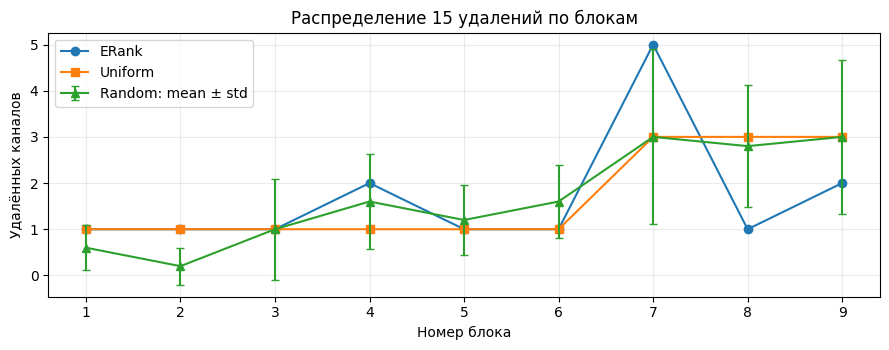

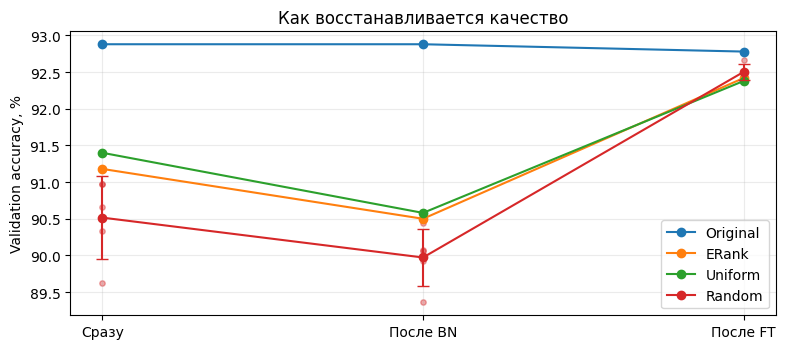

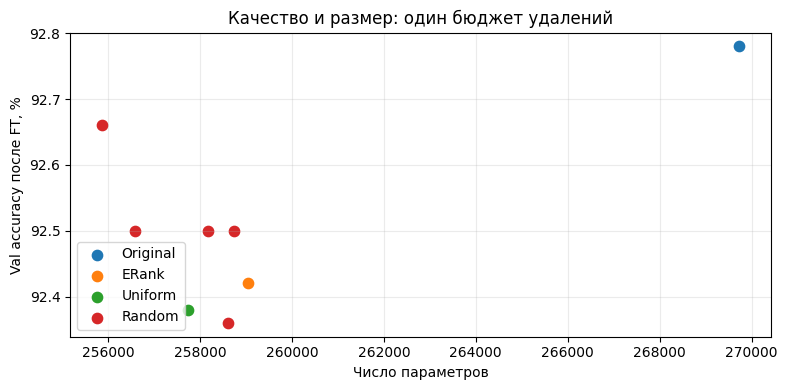

Результаты в results/erank_v2_full


In [20]:
x = np.arange(1, 10)
random_removed = np.stack([C - random_widths(s) for s in RANDOM_SEEDS])
plt.figure(figsize=(9, 3.6))
plt.plot(x, C-widths_erank, 'o-', label='ERank')
plt.plot(x, C-widths_uniform, 's-', label='Uniform')
plt.errorbar(x, random_removed.mean(0), yerr=random_removed.std(0),
             fmt='^-', capsize=3, label='Random: mean ± std')
plt.xlabel('Номер блока'); plt.ylabel('Удалённых каналов')
plt.title(f'Распределение {N} удалений по блокам')
plt.xticks(x); plt.grid(alpha=.25); plt.legend(); plt.tight_layout()
plt.savefig(OUT/'removed_by_block.png', dpi=150); plt.show()

plt.figure(figsize=(8, 3.6))
for name, group in report.groupby('method', sort=False):
    scores = group[['before', 'after_BN', 'after_FT']]
    line, = plt.plot(range(3), scores.mean().to_numpy(), marker='o', label=name)
    if len(group) > 1:
        plt.errorbar(range(3), scores.mean().to_numpy(),
                     yerr=scores.std().to_numpy(), fmt='none',
                     capsize=4, color=line.get_color())
        for stage in scores.columns:
            plt.scatter([scores.columns.get_loc(stage)]*len(group), scores[stage],
                        color=line.get_color(), s=15, alpha=.4)
plt.xticks(range(3), ['Сразу', 'После BN', 'После FT'])
plt.ylabel('Validation accuracy, %'); plt.title('Как восстанавливается качество')
plt.grid(alpha=.25); plt.legend(); plt.tight_layout()
plt.savefig(OUT/'accuracy_stages.png', dpi=150); plt.show()

plt.figure(figsize=(8, 4))
for name, group in report.groupby('method', sort=False):
    plt.scatter(group['params'], group['after_FT'], label=name, s=55)
plt.xlabel('Число параметров'); plt.ylabel('Val accuracy после FT, %')
plt.title('Качество и размер: один бюджет удалений')
plt.grid(alpha=.25); plt.legend(); plt.tight_layout()
plt.savefig(OUT/'accuracy_params.png', dpi=150); plt.show()
print('Результаты в', OUT)

## 8. Обучение архитектур с нуля (отдельный запуск)

**Это не дообучение после прунинга.** Создаём `ResNet20(widths)` с новой случайной инициализацией и обучаем на тех же train/validation. Сравниваем с соответствующей архитектурой, которая получилась прунингом и fine-tuning.

По умолчанию `RUN_SCRATCH=False`, чтобы случайное **«Выполнить все»** не запустило ещё несколько длительных обучений. Поставь `True`, когда будешь готов. По умолчанию берём один Random; для честной оценки разброса можно заменить `SCRATCH_RANDOM_SEEDS` на весь `RANDOM_SEEDS`.

Количество эпох `BASE_EPOCHS+FT_EPOCHS` примерно сопоставляет **общий бюджет эпох** с обучением Original + fine-tuning, но не делает расписания learning rate эквивалентными.

In [22]:
RUN_SCRATCH = False                 # включить вручную для обучения с нуля
SCRATCH_RANDOM_SEEDS = RANDOM_SEEDS[:1]   # или RANDOM_SEEDS — все 5 случайных архитектур

if RUN_SCRATCH:
    scratch_specs = [('ERank', widths_erank, None),
                     ('Uniform', widths_uniform, None)]
    scratch_specs += [('Random', random_widths(s), s) for s in SCRATCH_RANDOM_SEEDS]
    scratch_rows = []
    for name, w, seed in scratch_specs:
        seed_all(SEED + 2026)          # одинаковый seed инициализации
        fresh = ResNet20(w).to(DEVICE) # НИКАКИХ весов из original
        val = fit(fresh, BASE_EPOCHS + FT_EPOCHS, lr=0.1,
                  name=f'Scratch {name}/{seed}')
        scratch_rows.append({'method': name, 'seed': seed,
                             'params': nparams(fresh), 'scratch_val': val})
    scratch_report = pd.DataFrame(scratch_rows)
    scratch_report.to_csv(OUT/'scratch.csv', index=False)
    display(scratch_report.round(2))
    print('Сравнивай scratch_val с after_FT для ТОЙ ЖЕ архитектуры из runs.csv.')
else:
    print('Обучение с нуля пропущено. Измени RUN_SCRATCH=True, чтобы выполнить эту ячейку.')

Обучение с нуля пропущено. Измени RUN_SCRATCH=True, чтобы выполнить эту ячейку.


### Как читать результат

- **ERank vs Random**: проверяем, полезно ли *распределение* удалений по ERank, а не сам QR (QR общий).
- **ERank vs Uniform**: проверяем ERank против равномерной доли сжатия.
- **Сразу → BN → FT**: отделяем последствия удаления каналов, устаревших статистик BN и последующего восстановления весов.
- **Random mean ± std**: разброс по пяти распределениям при **одной исходной модели**. Это ещё не доверительный интервал по всем случайностям обучения.
- **Scratch vs FT**: нужна ли предобученная большая сеть, или найденная маленькая архитектура учится с нуля не хуже.

**Далее, но не сейчас:** повторить обучение исходной сети для нескольких seed и сравнить при близких *параметрах или FLOPs*, а не только одинаковом числе удалённых каналов. Если понадобится несколько бюджетов сжатия, придётся отдельно ввести коэффициент к ширинам ERank — это уже дополнительная эвристика, не прямой `ceil(ERank)`.